# Using the reliability Monte Carlo to get the Mean Time To Failure (MTTF)

Let's start by importing everything we will need:

In [1]:
from pandaict.reliability.monte_carlo import estimate_mttf_mttr
import networkx as nx
import matplotlib.pyplot as plt

For simplicity, we will start by declaring our (ICT) network using the graph library NetworkX. Later on I will show you how to do the same thing using a pandaICT network. \
In this tutorial we will start with a simple Network of 2 nodes connected by an edge.

In [2]:
# initialize the graph object
G = nx.Graph()

# add the two nodes
G.add_node("Source")
G.add_node("Target")

# and connect them with an edge (link) which has a failure rate (to demonstrate failure behavior).
mttf_edge = 10.0    # h
G.add_edges_from([("Source", "Target", {'mtbf_h': mttf_edge})])

We now have a graph of two nodes connected by an edge which fails (on average) after 10.0 hours (or any other arbitrary unit). \
Let's take a look at the graph by using the built-in plotting function of networkX. For that we'll have to specify a weight for each edge in the graph. After that we'll plot the graph:

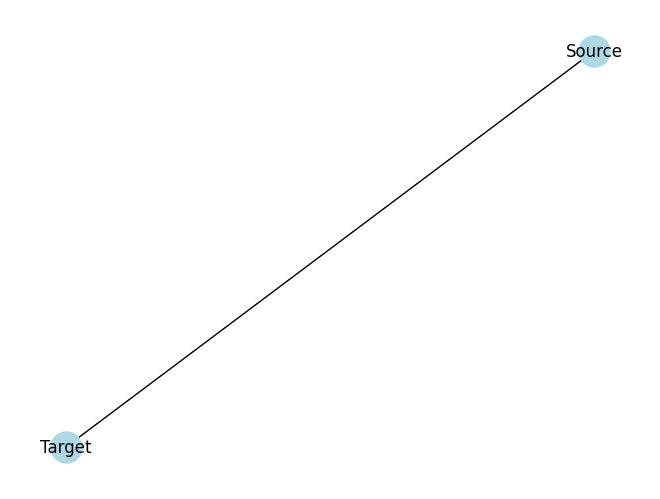

In [3]:
for u, v, data in G.edges(data=True):

    G[u][v]['weight'] = 1.0

nx.draw(G, with_labels=True, node_color='lightblue', node_size=500)
plt.show()

Looks all good? \
Then let's calculate the Mean Time To Failure (MTTF) of the system. Since we only set the edge to be failable, we would expect the system to have the same MTTF as the edge. Let's try it out:

In [4]:
res = estimate_mttf_mttr(G, sources="Source", targets="Target")
mttf = res["mttf"]
print("estimated MTTF of system to be ", mttf, "hours")

Running 1000 simulations in parallel...
estimated MTTF of system to be  9.746474919885 hours


The result should look pretty much as expected. Where we only get a deviation in the first decimal place. Let's look how far we are from the true solution and calculate the relative error:

In [5]:
err_rel = abs(mttf - mttf_edge)/mttf_edge * 100
print('relative Error of solution: ', err_rel, '%')

relative Error of solution:  2.5352508011500063 %


The solution should already be off by less than 5 % but we can do better. Let's increase the number of samples collected in the simulation. By default it is set to a 1000 samples. This time we will set it to a million samples and take a look at the error:

In [6]:
res = estimate_mttf_mttr(G, sources="Source", targets="Target", N=int(1e6))
mttf = res["mttf"]
print("estimated MTTF of system to be ", round(mttf, 2), "hours")
err_rel = abs(mttf - mttf_edge)/mttf_edge * 100
print('relative Error of improved solution: ', round(err_rel, 2), '%')

Running 1000000 simulations in parallel...
estimated MTTF of system to be  10.0 hours
relative Error of improved solution:  0.02 %


This time the error should be way below one percent, which demonstrated the accuracy of the approach.

In the next Tutorial we will take a look at ...